<a href="https://colab.research.google.com/github/keondreblankson/Week12/blob/main/KBlankson_WEEK12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Preprocessing Data for scikit-learn
Keondre Blankson  
IS 362

I used the UCI Mushroom dataset to compare odor and gill size with whether a mushroom is edible or poisonous. I changed the category codes into numbers and used tables and graphs to look for patterns.

## 1. Dataset and data dictionary
The dataset has 8,124 rows, 22 features, and one target column. UCI describes the records as hypothetical samples representing 23 species. The poisonous class also includes mushrooms with unknown edibility that were not recommended for eating.

Sources: [UCI dataset and data dictionary](https://archive.ics.uci.edu/dataset/73/mushroom), [original data](https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data), and [original description](https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.names).

I selected these columns. Column positions below start at 0.

| Column | Original position | Original codes and meanings | Numeric codes |
|---|---:|---|---|
| poisonous | 0 | e = edible; p = poisonous | e = 0; p = 1 |
| odor | 5 | a = almond; l = anise; c = creosote; y = fishy; f = foul; m = musty; n = none; p = pungent; s = spicy | a = 0; l = 1; c = 2; y = 3; f = 4; m = 5; n = 6; p = 7; s = 8 |
| gill_size | 8 | b = broad; n = narrow | b = 0; n = 1 |

The full dataset uses `?` for missing stalk-root values. Stalk root is not one of my selected columns; I check my subset for missing values below.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"
mushrooms = pd.read_csv(url, header=None, usecols=[0, 5, 8], na_values="?")
mushrooms.columns = ["poisonous", "odor", "gill_size"]
print("Rows and selected columns:", mushrooms.shape)
display(mushrooms.head())
print("Missing values:")
display(mushrooms.isna().sum())

Rows and selected columns: (8124, 3)


,poisonous,odor,gill_size
0,p,p,n
1,e,a,b
2,e,l,b
3,p,p,n
4,e,n,b


Missing values:


,0
poisonous,0
odor,0
gill_size,0


## 2. Convert the codes to numbers
I kept a copy of the original category codes so I can label the graphs clearly. The numeric odor values are category labels. A larger number does not mean a stronger or more dangerous odor.

In [2]:
original = mushrooms.copy()

class_map = {"e": 0, "p": 1}
odor_map = {"a": 0, "l": 1, "c": 2, "y": 3, "f": 4, "m": 5, "n": 6, "p": 7, "s": 8}
gill_map = {"b": 0, "n": 1}

mushrooms["poisonous"] = mushrooms["poisonous"].map(class_map)
mushrooms["odor"] = mushrooms["odor"].map(odor_map)
mushrooms["gill_size"] = mushrooms["gill_size"].map(gill_map)

# Make sure the mappings did not leave missing or unrecognized values.
assert not mushrooms.isna().any().any()
mushrooms = mushrooms.astype(int)
display(mushrooms.head())
print("Data types:")
display(mushrooms.dtypes)

,poisonous,odor,gill_size
0,1,7,1
1,0,0,0
2,0,1,0
3,1,7,1
4,0,6,0


Data types:


,0
poisonous,int64
odor,int64
gill_size,int64


## 3. Distributions of the selected columns
The tables show the count and percentage of each category. The bar charts show the same distributions.

poisonous


,Category,Numeric code,Count,Percent
0,Edible,0,4208,51.8
1,Poisonous,1,3916,48.2


odor


,Category,Numeric code,Count,Percent
0,Almond,0,400,4.92
1,Anise,1,400,4.92
2,Creosote,2,192,2.36
3,Fishy,3,576,7.09
4,Foul,4,2160,26.59
5,Musty,5,36,0.44
6,None,6,3528,43.43
7,Pungent,7,256,3.15
8,Spicy,8,576,7.09


gill_size


,Category,Numeric code,Count,Percent
0,Broad,0,5612,69.08
1,Narrow,1,2512,30.92


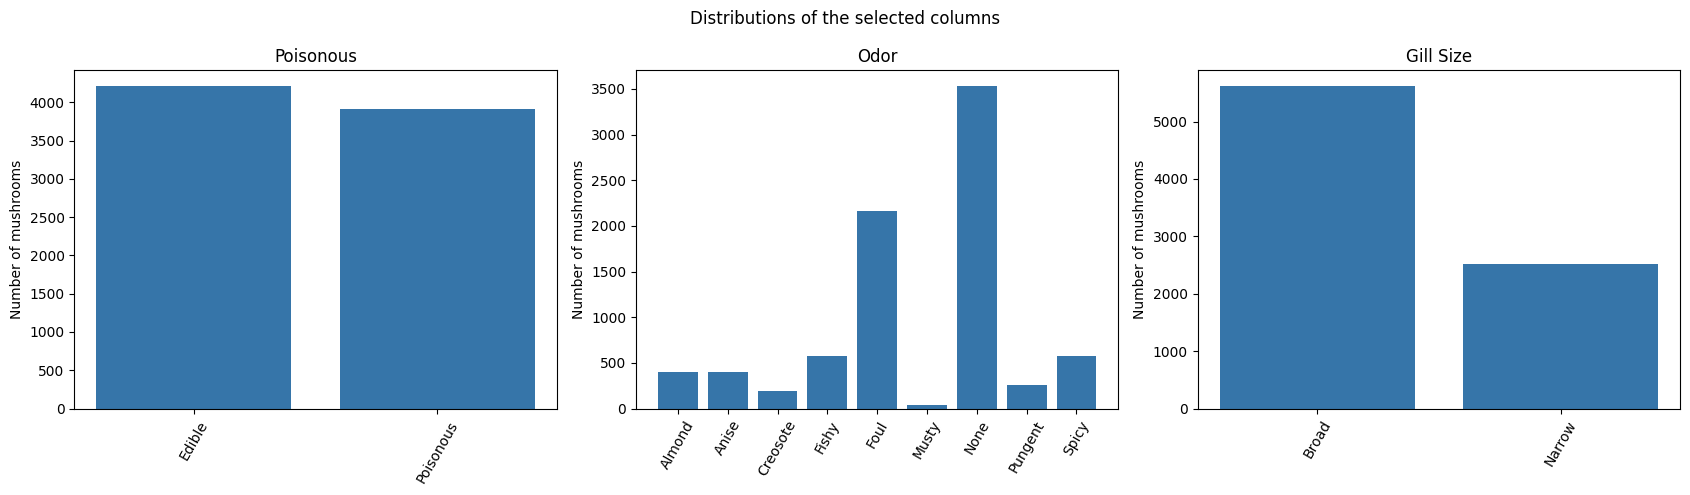

In [3]:
class_labels = ["Edible", "Poisonous"]
odor_labels = ["Almond", "Anise", "Creosote", "Fishy", "Foul", "Musty", "None", "Pungent", "Spicy"]
gill_labels = ["Broad", "Narrow"]
labels = {"poisonous": class_labels, "odor": odor_labels, "gill_size": gill_labels}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, column in zip(axes, mushrooms.columns):
    counts = mushrooms[column].value_counts().sort_index()
    summary = pd.DataFrame({"Category": [labels[column][i] for i in counts.index],
                            "Numeric code": counts.index,
                            "Count": counts.values,
                            "Percent": (counts.values / len(mushrooms) * 100).round(2)})
    print(column)
    display(summary)
    ax.bar(summary["Category"], summary["Count"], color="#3675a9")
    ax.set_title(column.replace("_", " ").title())
    ax.set_ylabel("Number of mushrooms")
    ax.tick_params(axis="x", rotation=60)
fig.suptitle("Distributions of the selected columns")
plt.tight_layout()
plt.show()

## 4. Scatterplots
I added small, reproducible random offsets (jitter) to separate overlapping points. The underlying data stays unchanged. The vertical positions still represent edible (0) and poisonous (1); the offsets have no numerical meaning.

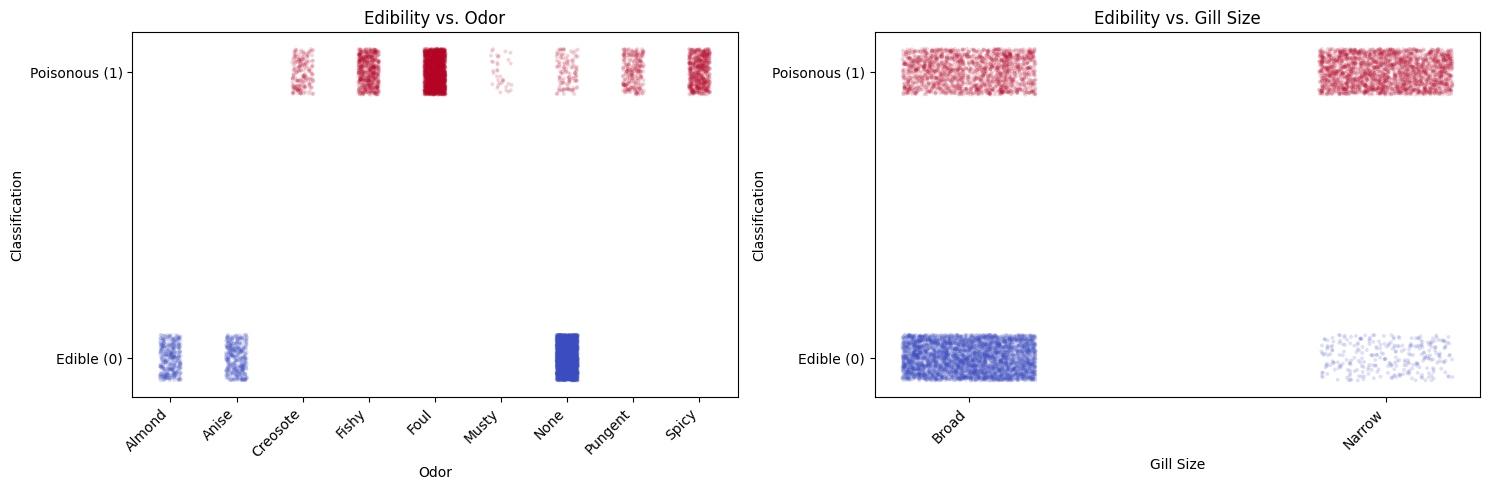

In [4]:
rng = np.random.default_rng(362)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, column in zip(axes, ["odor", "gill_size"]):
    x = mushrooms[column] + rng.uniform(-0.16, 0.16, len(mushrooms))
    y = mushrooms["poisonous"] + rng.uniform(-0.08, 0.08, len(mushrooms))
    ax.scatter(x, y, c=mushrooms["poisonous"], cmap="coolwarm", vmin=0, vmax=1,
               s=8, alpha=0.16, edgecolors="none")
    ax.set_xticks(range(len(labels[column])))
    ax.set_xticklabels(labels[column], rotation=45, ha="right")
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Edible (0)", "Poisonous (1)"])
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Classification")
    ax.set_title("Edibility vs. " + column.replace("_", " ").title())
plt.tight_layout()
plt.show()

## 5. Compare each feature with edibility
Because points overlap in the scatterplots, I also used cross-tabulations to check the exact counts and the percentage poisonous in each category.

In [5]:
for column in ["odor", "gill_size"]:
    table = pd.crosstab(mushrooms[column], mushrooms["poisonous"]).reindex(columns=[0, 1], fill_value=0)
    table.columns = ["Edible", "Poisonous"]
    table.index = [labels[column][i] for i in table.index]
    table.index.name = column
    table["Percent poisonous"] = (100 * table["Poisonous"] / table[["Edible", "Poisonous"]].sum(axis=1)).round(2)
    display(table)

,Edible,Poisonous,Percent poisonous
odor,,,
Almond,400,0,0.0
Anise,400,0,0.0
Creosote,0,192,100.0
Fishy,0,576,100.0
Foul,0,2160,100.0
Musty,0,36,100.0
None,3408,120,3.4
Pungent,0,256,100.0
Spicy,0,576,100.0


,Edible,Poisonous,Percent poisonous
gill_size,,,
Broad,3920,1692,30.15
Narrow,288,2224,88.54


## 6. Preliminary conclusions
There are 4,208 edible mushrooms and 3,916 poisonous mushrooms, so the two classes are fairly balanced. Odor looks useful for predicting edibility in this dataset. All mushrooms with almond or anise odors are edible, while all mushrooms with creosote, fishy, foul, musty, pungent, or spicy odors are poisonous. However, no odor does not always mean edible. There are 3,408 edible mushrooms and 120 poisonous mushrooms with no odor.

Gill size also shows a pattern. About 88.54% of narrow-gilled mushrooms are poisonous, compared with 30.15% of broad-gilled mushrooms. Both gill sizes include edible and poisonous examples, so gill size alone does not completely separate the classes. Based on these tables, odor appears more helpful than gill size, but a trained model and separate test data would be needed to measure predictive performance.

The selected columns now contain numeric values and have no missing values. For a later model that treats numeric distances as meaningful, I would one-hot encode odor because these category numbers have no natural order. These findings describe this dataset and should not be used to decide whether a wild mushroom is safe to eat.